# mc_pm6_3 Escaped Asteroid Analysis
The run_log_analysis python script summarises the hdf5 log files into an escaped_asteroids pandas DataFrame. This DataFrame has details of the parameter and time that the asteroid exceeds the various parameters that are monitored. 

In [1]:
import datetime as datetime

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm

xlabel_time = 'Years after start of simulation [$10^8 ~ yr$]'

In [2]:
# Read the clone assignments file
pa_mvc3 = pd.read_hdf('../../asteroid_data/sim_data/mc_pm6_3/inputs/clone_assignments.h5')
# Read the escaped asteroids file
ea_mvc3 = pd.read_hdf('../../asteroid_data/sim_data/mc_pm6_3/escaped_asteroids.h5')


In [125]:
sim_particles= ea_mvc3[['sim_no','particle_number']].drop_duplicates()

sim_groups = sim_particles.groupby('sim_no').agg(Count_Sim = ('sim_no','count')).apply(lambda x: x==3)

dont_run = sim_groups[sim_groups.Count_Sim].index

print(dont_run)

Index(['00131', '00133', '00136', '00142', '00145', '00146', '00147', '00148',
       '00150', '00160',
       ...
       '18894', '18896', '18897', '18901', '18905', '18906', '18907', '18910',
       '18913', '18914'],
      dtype='object', name='sim_no', length=654)


In [4]:
# Strip the spaces out of the names of the asteroids
ea_mvc3['ast_name'] = [x.replace(' ','') for x in ea_mvc3.ast_name]
# Set the asteroid name as the index
ea_mvc3.set_index('ast_name', inplace=True)
ea_mvc3.describe()

,particle_number,parameter,parameter_value,integration_year
count,17908.000000,17908.000000,17908.000000,1.790800e+04
mean,9.259270,6.737771,2.445939,1.750063e+09
std,0.799048,0.746338,5.757332,1.776461e+09
min,8.000000,6.000000,0.000000,1.000000e+04
25%,9.000000,6.000000,0.340863,2.846663e+08
50%,9.000000,7.000000,0.381470,1.053175e+09
75%,10.000000,7.000000,0.721473,2.844060e+09
max,10.000000,8.000000,78.797254,6.283185e+09


In [5]:
print(f"Mars/Ceres Mercurious escaped asteroids:{(ea_mvc3.index+ea_mvc3['vectors']).nunique()}")


Mars/Ceres Mercurious escaped asteroids:9944


In [6]:
ea_mvc3.sort_values(by=['ast_name', 'vectors']).head(20)

,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
ast_name,,,,,,
104287,XYZVXVYVZ,02469,8,6,4.815804,5.774826e+09
104287,XYZVXVYVZ,02469,8,7,0.359443,5.133878e+09
104287,XYZVXVYVZ,02469,8,8,0.550722,5.723927e+09
104287,XcmYcmZcpVXcmVYcmVZcp,02459,8,6,15.901978,2.952769e+09
104287,XcmYcmZcpVXcmVYcmVZcp,02459,8,7,0.390441,2.910668e+09
104287,XcmYcmZcpVXcmVYcmVZcp,02459,8,8,0.555398,2.930148e+09
104287,XcmYcpZcmVXcmVYcpVZcm,02450,8,7,0.342921,6.210293e+09
104287,XcmYcpZcmVXcmVYcpVZcm,02450,8,8,1.338067,6.222232e+09
104287,XcmYcpZcpVXcmVYcpVZcm,02442,8,6,5.842359,4.270483e+09


In [7]:
print(ea_mvc3.groupby(['parameter']).max())
print(ea_mvc3.groupby(['parameter']).min())

                         vectors sim_no  particle_number  parameter_value   
parameter                                                                   
6          XcpYcpZcpVXcpVYcpVZcp  18914               10        78.797254  \
7          XcpYcpZcpVXcpVYcpVZcp  18914               10         0.935531   
8          XcpYcpZcpVXcpVYcpVZcp  18914               10         2.814871   

           integration_year  
parameter                    
6              6.283185e+09  
7              6.282557e+09  
8              6.283185e+09  
             vectors sim_no  particle_number  parameter_value   
parameter                                                       
6          XYZVXVYVZ  00005                8         0.000000  \
7          XYZVXVYVZ  00005                8         0.340001   
8          XYZVXVYVZ  00005                8         0.550016   

           integration_year  
parameter                    
6                   10000.0  
7                   10000.0  
8                 

In [8]:
ea_mvc3.groupby(['ast_name']).head()

,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
ast_name,,,,,,
16794,XcpYcmZcpVXcpVYcmVZcp,00148,8,6,4.118940,6.208498e+08
499395,XcpYcmZcpVXcpVYcmVZcp,00148,9,6,0.000000,6.214782e+08
2002FL44,XcpYcmZcpVXcpVYcmVZcp,00148,10,6,7.460342,5.435590e+08
16794,XcpYcmZcpVXcpVYcmVZcp,00148,8,7,0.429269,5.957146e+08
2002FL44,XcpYcmZcpVXcpVYcmVZcp,00148,10,7,0.448423,4.964305e+08
...,...,...,...,...,...,...
2010MD2,XcmYcpZcpVXcpVYcmVZcp,13099,10,6,0.000000,1.068885e+09
2010MD2,XcmYcpZcpVXcpVYcmVZcp,13099,10,7,0.345306,6.459850e+08
2010MD2,XcmYcpZcpVXcpVYcmVZcp,13099,10,8,0.554396,6.428431e+08


In [9]:
escapee_years = ea_mvc3.loc[ea_mvc3.parameter == 6][['vectors', 'integration_year']]
escapee_years['integration_year'] = escapee_years.integration_year/(2*np.pi)
escapee_years

,vectors,integration_year
ast_name,,
16794,XcpYcmZcpVXcpVYcmVZcp,9.881132e+07
499395,XcpYcmZcpVXcpVYcmVZcp,9.891133e+07
2002FL44,XcpYcmZcpVXcpVYcmVZcp,8.651010e+07
499395,XcmYcpZcmVXcmVYcpVZcp,1.802193e+08
2002FL44,XcmYcpZcmVXcmVYcpVZcp,2.360391e+07
...,...,...
2014WW437,XcmYcmZcmVXcmVYcmVZcm,6.610810e+07
2008RY179,XcmYcmZcmVXcmVYcmVZcm,6.640813e+07
2010MD2,XcmYcpZcpVXcpVYcmVZcp,1.701183e+08


Text(0.5, 0, 'Years after start of simulation [$10^8 ~ yr$]')

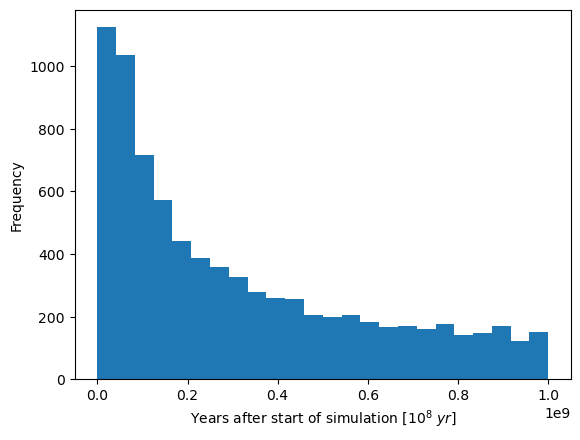

In [10]:
plt.hist(escapee_years.integration_year, bins='auto')
plt.ylabel('Frequency')
plt.xlabel(xlabel_time)

In [11]:
path = '../../asteroid_data/luthera_family.h5'
luth_fam = pd.read_hdf(path)
luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])
mag_h = 17
p_v = 0.0387
luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))
print(luth_fam.head())

  ast_name  abs_mag       a_P       e_P   sineI_P family_id      irad   
0     1303     9.48  3.219248  0.121842  0.322276      1303  0.328133  \
1    11911    11.80  3.210027  0.132169  0.330567      1303  0.336904   
2    16794    13.45  3.229767  0.120773  0.321221      1303  0.327019   
3    17840    12.46  3.227073  0.122213  0.322861      1303  0.328751   
4    26558    13.15  3.194646  0.115763  0.319342      1303  0.325035   

        ideg       diam  
0  18.800624  85.836005  
1  19.303194  29.489642  
2  18.736782  13.793342  
3  18.836035  21.760531  
4  18.623137  15.836875  


In [12]:
luth_fam = luth_fam.set_index('ast_name')

In [13]:
escaped_asts = ea_mvc3.index.unique()
len(escaped_asts)
print(escaped_asts)

Index(['16794', '499395', '2002FL44', '2002PX190', '2002NO62', '505088',
       '33292', '17840', '2002GM31', '500005',
       ...
       '2008HJ32', '2015XQ433', '2010OY98', '2014WO409', '2010MO87',
       '2014WW437', '2008RY179', '2015XE390', '2010NM106', '2010MD2'],
      dtype='object', name='ast_name', length=393)


In [14]:
luth_fam[luth_fam.index.isin(escaped_asts)==True]

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
ast_name,,,,,,,,
16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342
17840,12.46,3.227073,0.122213,0.322861,1303,0.328751,18.836035,21.760531
33292,12.99,3.227360,0.129485,0.326713,1303,0.332824,19.069389,17.047845
44492,13.69,3.220273,0.123425,0.324298,1303,0.330270,18.923050,12.350072
48296,13.44,3.224273,0.128330,0.326302,1303,0.332389,19.044475,13.857009
...,...,...,...,...,...,...,...,...
2013BG20,17.56,3.195066,0.141433,0.336048,1303,0.342718,19.636279,2.078115
2013BH34,17.37,3.198605,0.128226,0.327383,1303,0.333533,19.110011,2.268138
2013CE106,17.04,3.199622,0.138950,0.332601,1303,0.339060,19.426722,2.640399


In [15]:
ey_years = escapee_years.groupby(by=escapee_years.index)
mean_escape = ey_years.mean('integration_year')

mean_escape['vec_count'] = ey_years.vectors.count()

escapee_years.sort_values('integration_year')
luth_fam[luth_fam.index.isin(escapee_years.index)==True]

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
ast_name,,,,,,,,
16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342
17840,12.46,3.227073,0.122213,0.322861,1303,0.328751,18.836035,21.760531
33292,12.99,3.227360,0.129485,0.326713,1303,0.332824,19.069389,17.047845
44492,13.69,3.220273,0.123425,0.324298,1303,0.330270,18.923050,12.350072
48296,13.44,3.224273,0.128330,0.326302,1303,0.332389,19.044475,13.857009
...,...,...,...,...,...,...,...,...
2013BG20,17.56,3.195066,0.141433,0.336048,1303,0.342718,19.636279,2.078115
2013BH34,17.37,3.198605,0.128226,0.327383,1303,0.333533,19.110011,2.268138
2013CE106,17.04,3.199622,0.138950,0.332601,1303,0.339060,19.426722,2.640399


In [16]:
counts, bins = np.histogram(mean_escape.vec_count, 4)
mean_escape['quartiles'] = np.digitize(mean_escape.vec_count, bins)

In [17]:
luth_fam['integration_year'] = mean_escape.integration_year
luth_fam['quartiles'] = mean_escape.quartiles

luth_fam = luth_fam.fillna(value={'integration_year': 0, 'vec_count': 0})
luth_fam['graph_symbol'] = '.'
luth_fam.loc[luth_fam['integration_year']!=0,['graph_symbol']] = 'o'
len(luth_fam[luth_fam['integration_year']!=0])

366

In [18]:
def flash_plot(ax, ast_data, y_column, x_column='a_P'):
    for graph_symbol, m_fam in ast_data.groupby('graph_symbol'):
        if graph_symbol == '.':
            stab = ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors='white', marker='P', 
            c='black', label='Stable Asteroid')
        else:
            cm_yr = mpl.colormaps['inferno'] 
            norm_vecs = m_fam['quartiles']*40
            colour_values = m_fam['integration_year']
            esc = ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors='black', marker=graph_symbol, 
                c=colour_values, cmap = cm_yr, s=norm_vecs, label='Quartile')
                
            cb = plt.colorbar(esc, label=xlabel_time, location='bottom')
    
    esc_elements = esc.legend_elements("sizes", num=4)
    stab_elements = stab.legend_elements("sizes", num=1)
        
    plt.legend(handles = stab_elements[0] + esc_elements[0], 
               labels=['Stable', '<25% Clones', '25-50% Clones','51-75% Clones', '>75% Clones'],
               bbox_to_anchor=(1.0, 1.0))


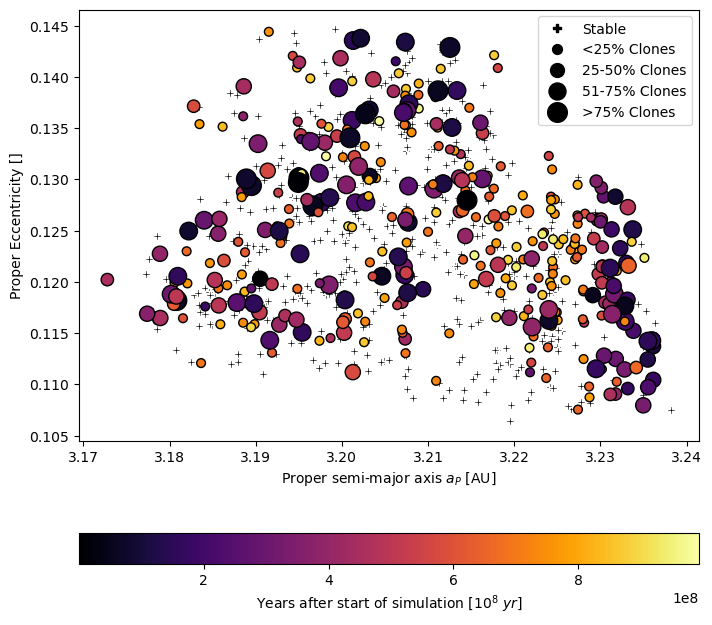

In [19]:
fig = plt.figure(figsize=(8, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'e_P')

plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Eccentricity []")
plt.show()

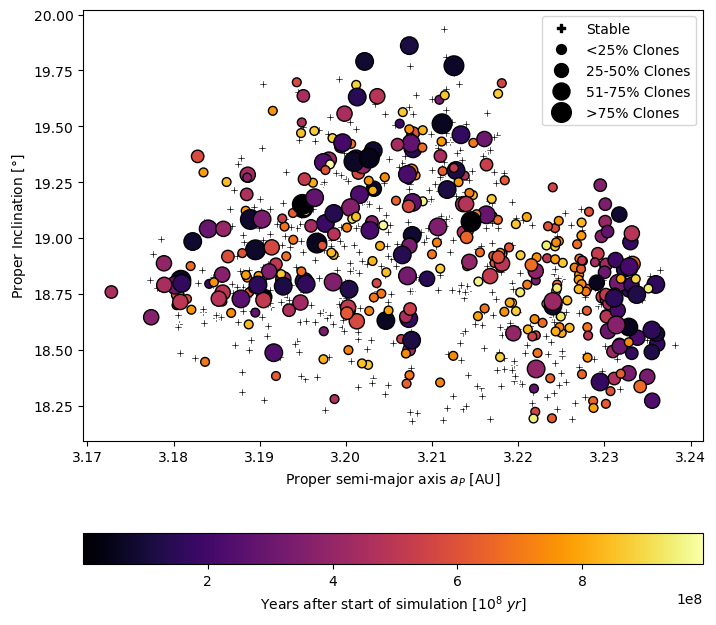

In [20]:
fig = plt.figure(figsize=(8, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'ideg')
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Inclination [$\degree$]")
plt.show()

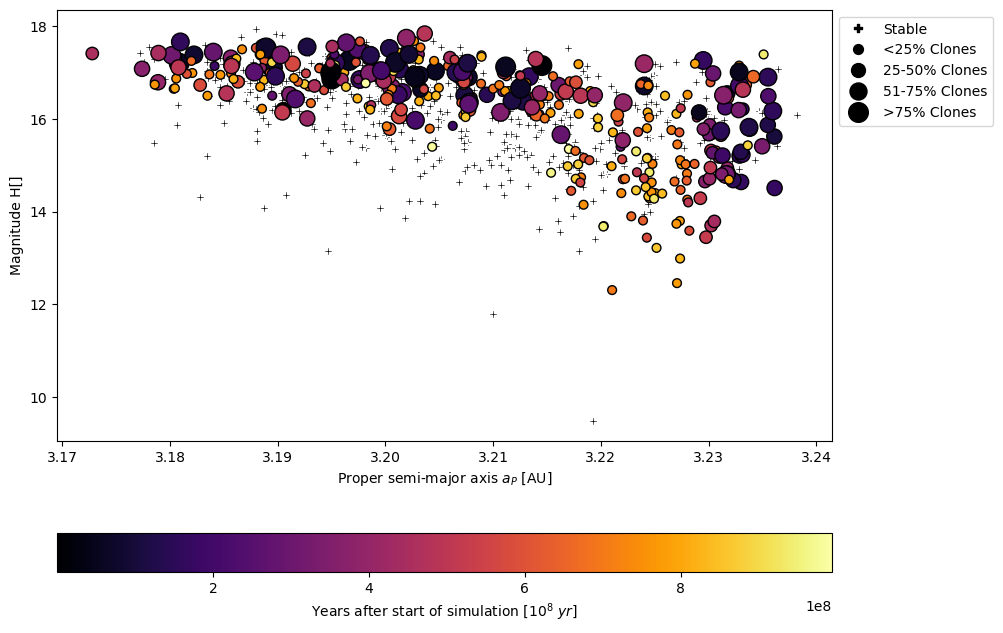

In [21]:
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'abs_mag')
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Magnitude H[]")
plt.show()

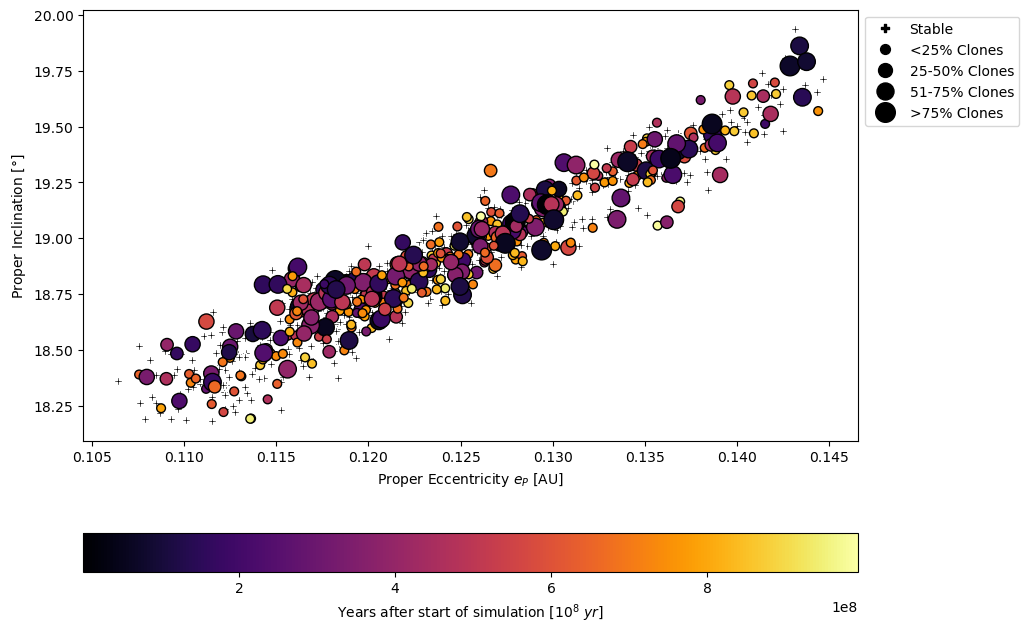

In [22]:
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'ideg', 'e_P')
    
plt.xlabel("Proper Eccentricity $e_P$ [AU]")
plt.ylabel("Proper Inclination [$\degree$]")
plt.show()

In [23]:
def hist_ratio(data, col_name, x_label):
    stable_cnts, bins = np.histogram(data[data.integration_year == 0][col_name],bins='auto')  
    escp_cnts, bins = np.histogram(data[data.integration_year != 0][col_name],bins=bins)
    ratio = ((stable_cnts)/(stable_cnts+escp_cnts+1.0e-40))*100

    fig = plt.figure(figsize=(8, 8))
    ax0 = plt.subplot(111)
    ax1 = ax0.twinx()
    ax0.hist([data[data.integration_year == 0][col_name], 
                  data[data.integration_year != 0][col_name]], bins=bins, stacked=True)
    ax0.set_ylabel("Frequency")
    ax0.set_xlabel(x_label)
    ax0.legend(labels=['Stable', 'Escaped'])


    ax1.plot(bins[:-1]+(bins[1]-bins[0])/2,ratio, c='grey', marker='+')
    ax1.set_ylim(0,100)
    ax1.set_ylabel("Asteroid Stability [%]")
    plt.show()
    

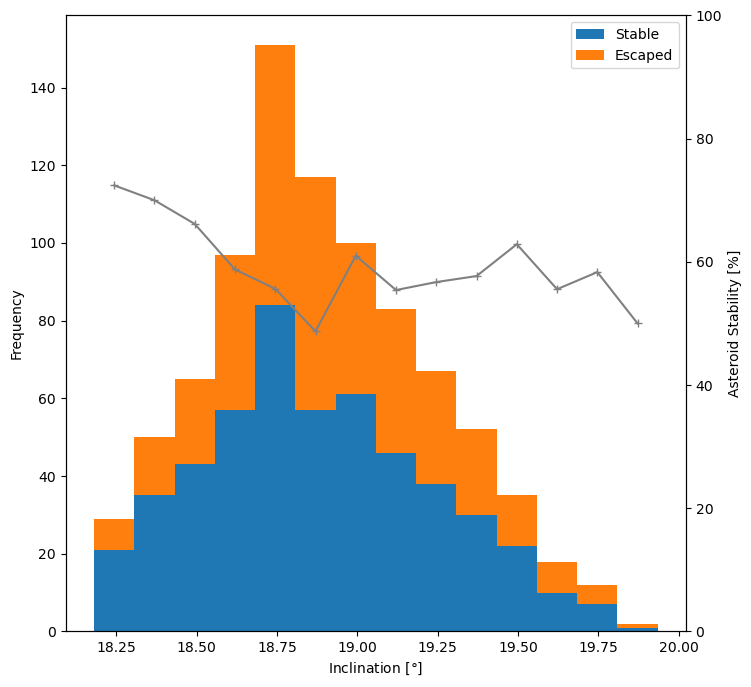

In [24]:
hist_ratio(luth_fam, 'ideg', "Inclination [$\degree$]")

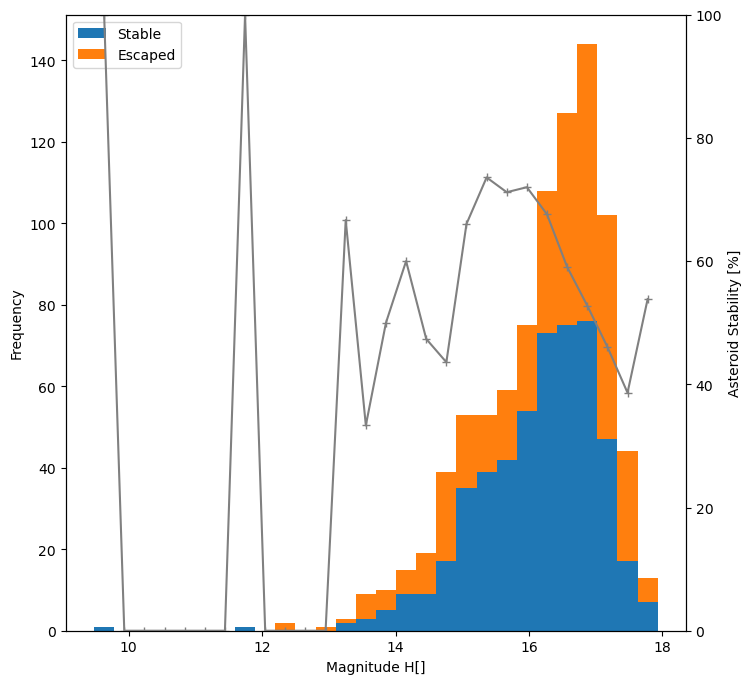

In [25]:
hist_ratio(luth_fam, 'abs_mag', "Magnitude H[]")

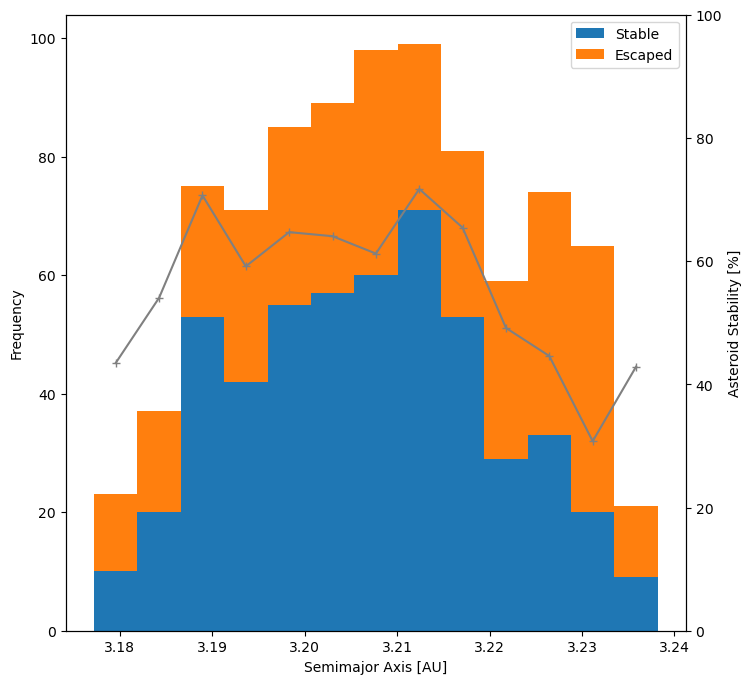

In [26]:
hist_ratio(luth_fam, 'a_P', "Semimajor Axis [AU]")

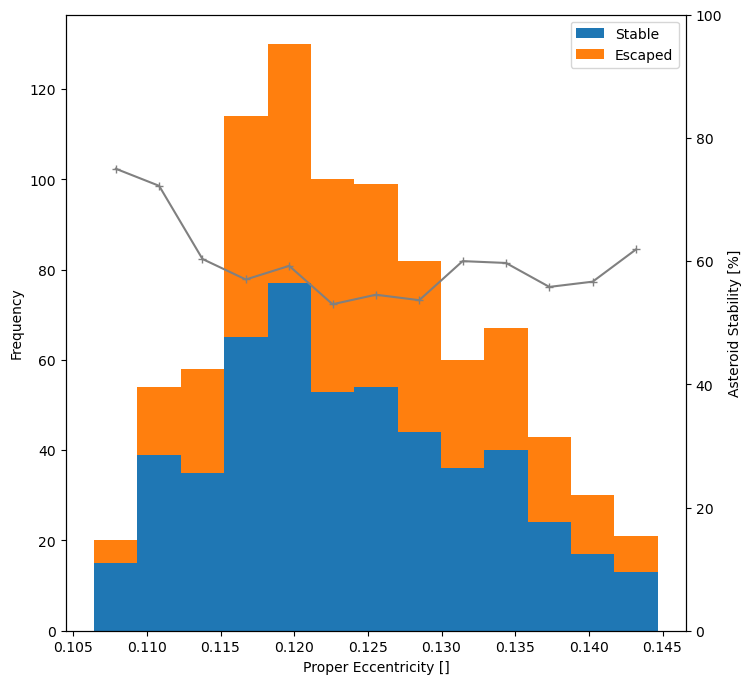

In [27]:
hist_ratio(luth_fam, 'e_P', "Proper Eccentricity []")